# 16. Rules of thumb, tested

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1, 3, 4 and 11

**Reading:** Taylor, ch. 2 and 3 · Bevington & Robinson, ch. 3 ·
Tellinghuisen (2001)

Every laboratory course hands its students a set of short rules: add the
errors, overlapping error bars mean agreement, quote one significant figure,
ignore the small terms, and so on. They are passed from one course guide to
the next because they are quick, and most of them are right *somewhere*.
The trouble is that the guides rarely say where.

This notebook takes nine such rules, each found in one or more widely used
guides (listed at the end), and tests them the way the rest of this
repository tests everything: by simulating many experiments in which the
true answer is known. For each rule the question is the same: in which
regime does it hold, and how wrong is it outside that regime?

| Section | Rule |
|---|---|
| 5.1 | Add the errors (worst case), or use the upper and lower bounds |
| 5.2 | Overlapping error bars mean the results agree |
| 5.3 | The linear propagation formula is fine for small uncertainties |
| 5.4 | Apply the rules for sums and products step by step |
| 5.5 | Measure many periods (or objects) at once |
| 5.6 | Keep only the largest contribution |
| 5.7 | Significant figures carry the uncertainty |
| 5.8 | A systematic error of the meter does not affect the slope |
| 5.9 | Uncertainty can only grow through a calculation |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(5)

## 16.1 Worst case or quadrature?

**The rule.** Several introductory guides teach that the uncertainties of a
sum or difference are *added*, $\Delta z = \Delta x + \Delta y$, and those of
a product or quotient are added as relative uncertainties. An equivalent
recipe is the *upper–lower bound* method: evaluate the formula with every
input pushed to the end of its range that makes the result largest, then
smallest, and quote the larger excursion. Both are *worst-case* methods.

**What the worst case means.** The two methods answer different questions.
Quadrature (Chapter 3) gives a standard uncertainty: the standard deviation
of the result, with the same meaning (about 68 % for a normal distribution)
however many inputs there are. The worst case gives the largest error that
can occur *if each input error is at most its stated value*. That is the
right question in tolerance analysis, where the $\pm$ values are hard limits
and a part must fit every time. It is the wrong question when the $\pm$
values are standard uncertainties, which can be exceeded. Mixing the two, a
worst-case calculation whose result is then read as a 68 % interval, is the
common error.

**The test.** Add $n$ independent errors, each with standard deviation $u$,
and count how often the actual total falls within $\pm\sqrt{n}\,u$
(quadrature) and within $\pm n u$ (linear addition of the standard
uncertainties).

In [2]:
n_values = np.arange(1, 13)
n_trials = 200_000
cover_quad, cover_lin, cover_lin_bound, cover_half_bound = [], [], [], []
for n in n_values:
    e_norm = rng.normal(0, 1, (n_trials, n)).sum(axis=1)
    a = np.sqrt(3.0)                                   # rectangular errors with u = 1 have half-width sqrt(3)
    e_rect = rng.uniform(-a, a, (n_trials, n)).sum(axis=1)
    cover_quad.append(np.mean(np.abs(e_norm) < np.sqrt(n)))
    cover_lin.append(np.mean(np.abs(e_norm) < n))
    cover_lin_bound.append(np.mean(np.abs(e_rect) < n * a))           # always 1: it is a bound
    cover_half_bound.append(np.mean(np.abs(e_rect) > 0.5 * n * a))     # how often the error exceeds half the bound

print(" n   P(within quadrature u)   P(within linear sum)   ratio linear/quadrature")
for n, cq, cl in zip(n_values, cover_quad, cover_lin):
    if n in (1, 2, 3, 5, 10):
        print(f"{n:2d}          {cq:.3f}                  {cl:.3f}                {np.sqrt(n):.2f}")
print(f"\nrectangular errors, n = 5: P(total error > half the worst-case bound) = {cover_half_bound[4]:.3f}")

 n   P(within quadrature u)   P(within linear sum)   ratio linear/quadrature
 1          0.681                  0.681                1.00
 2          0.681                  0.842                1.41
 3          0.681                  0.916                1.73
 5          0.682                  0.974                2.24
10          0.683                  0.999                3.16

rectangular errors, n = 5: P(total error > half the worst-case bound) = 0.051


With quadrature the coverage stays at 68 % whatever the number of terms.
With linear addition it climbs from 68 % for one term to 84 % for two and
99.8 % for ten: the meaning of the number after the $\pm$ changes with the
length of the formula, and a reader cannot tell what it means.

For hard limits (rectangular errors of half-width $a$), the linear sum is a
guaranteed bound, as intended. It is also pessimistic: for five such terms,
the actual error exceeds even *half* the worst-case bound in only about 5 %
of cases (printed above). This is why tolerance engineers distinguish
worst-case stack-up from statistical ("root-sum-square") stack-up and choose
deliberately.

### The upper–lower bound method on two worked examples

The first example is an average speed, $v = \Delta x/\Delta t$ with
$\Delta x = 30.0 \pm 0.5$ m and $\Delta t = 2.0 \pm 0.1$ s. The second is a
capacitance $C \propto \kappa D^2/d$ with relative uncertainties of 2 % in
the diameter $D$, 5 % in the gap $d$ and 10 % in the dielectric constant
$\kappa$.

In [3]:
def bounds(f, x, u, signs):
    """Upper-lower bound: push each input to the end of its range given by signs."""
    x, u, signs = map(np.asarray, (x, u, signs))
    return f(*(x + signs * u)) - f(*x), f(*x) - f(*(x - signs * u))

speed = lambda dx, dt: dx / dt
cap = lambda kappa, D, d: kappa * D**2 / d           # relative quantities: all equal to 1 nominally

for name, f, x, u, signs in (("speed", speed, [30.0, 2.0], [0.5, 0.1], [1, -1]),
                             ("capacitance (relative)", cap, [1.0, 1.0, 1.0], [0.10, 0.02, 0.05], [1, 1, -1])):
    up, down = bounds(f, x, u, signs)
    y, uq = ep.propagate(f, x, u)
    mc = ep.summarize(ep.monte_carlo(f, x, u, n=400_000, rng=rng))
    print(f"{name}: value {y:.3f}")
    print(f"   upper-lower bound : +{up:.3f} / -{down:.3f}")
    print(f"   quadrature        :  {uq:.3f}")
    print(f"   Monte Carlo (68 %): +{mc['high'] - y:.3f} / -{y - mc['low']:.3f}")

speed: value 15.000
   upper-lower bound : +1.053 / -0.952
   quadrature        :  0.791
   Monte Carlo (68 %): +0.834 / -0.754
capacitance (relative): value 1.000
   upper-lower bound : +0.205 / -0.177
   quadrature        :  0.119
   Monte Carlo (68 %): +0.122 / -0.117


For the speed, with two inputs, the bounds are about 25 % wider than the
68 % interval. For the capacitance, with three inputs, they are 60 % wider.
The bounds do capture one real feature that quadrature misses, the
asymmetry of a nonlinear function, and the Monte Carlo interval shows the
same asymmetry at its proper width.

**Verdict.** Use worst-case addition when the $\pm$ values are hard limits
and a guarantee is needed (fits, clearances, safety margins), and say so.
For standard uncertainties use quadrature, or Monte Carlo when the
asymmetry matters. Do not read a worst-case result as a 68 % interval.

## 16.2 Do overlapping error bars mean agreement?

**The rule.** Two results agree if their error bars overlap; one guide adds
that bars which barely touch correspond to a difference of about two
standard deviations, or a 5 % chance.

**The test.** For two independent results with standard uncertainties
$u_1$ and $u_2$, the error bars overlap when
$|x_1 - x_2| < u_1 + u_2$. In units of the standard uncertainty of the
*difference*, $\sqrt{u_1^2 + u_2^2}$ (Section 1.6), the threshold is

$$ z_\text{overlap} = \frac{u_1 + u_2}{\sqrt{u_1^2 + u_2^2}} , $$

which is $\sqrt 2 = 1.41$ for equal uncertainties and approaches 1 when one
is much larger. Bars that just touch are therefore 1.41 standard deviations
apart, not 2. If both results measure the same true value, bars fail to
overlap with probability $2[1 - \Phi(1.41)] = 0.16$, one pair in six.

In [4]:
r = np.linspace(0.01, 1, 200)                       # u2 / u1
z_thr = (1 + r) / np.sqrt(1 + r**2)
p_no_overlap = 2 * stats.norm.sf(z_thr)

# check by simulation for equal uncertainties
x1 = rng.normal(0, 1, 500_000); x2 = rng.normal(0, 1, 500_000)
print(f"equal u: threshold z = {np.sqrt(2):.3f}")
print(f"         P(no overlap | same true value): formula {2 * stats.norm.sf(np.sqrt(2)):.3f}, "
      f"simulation {np.mean(np.abs(x1 - x2) > 2):.3f}")
print(f"         P(2-sigma bars fail to overlap):  {2 * stats.norm.sf(2 * np.sqrt(2)):.4f}")

equal u: threshold z = 1.414
         P(no overlap | same true value): formula 0.157, simulation 0.157
         P(2-sigma bars fail to overlap):  0.0047


The overlap rule is a test of agreement at roughly the 84 % level for equal
uncertainties and the 68 % level for very unequal ones, an inconsistent
standard in either case. The reverse reading is also popular: if bars of
$\pm 2u$ do *not* overlap, the difference is significant. That test is
very conservative, with a false-alarm rate of 0.5 % instead of 5 %.

**Verdict.** Compute $z = |x_1 - x_2|/\sqrt{u_1^2 + u_2^2}$ and say what
probability corresponds to it. It takes one line, and it is what the eye
is trying, and failing, to do. (The same misreading of error bars is well
documented among practising researchers; see Cumming and Finch, 2005.)

## 16.3 How small is "small"? Limits of the linear formula

**Two rules.** One guide states that the derivative formula agrees with the
exact upper and lower values "if the relative error on $x$ is small", below
about 15 %. Tellinghuisen (2001) proposes a different "10 % rule": the
linear result can be trusted to about 10 % when the relative standard
uncertainty of the *output* is below 10 %.

The two criteria differ when the function amplifies relative errors. The
same guide's own example is $J = x^{10}$ with $x = 5.0 \pm 0.2$ m, a 4 %
input uncertainty. The linear formula gives $\pm 40$ %. The function is
monotonic, so the bounds of $x$ map onto bounds of $J$:

In [5]:
q = 0.04
print(f"x^10 with 4 % on x: linear +/- {10 * q:.0%};  "
      f"exact bounds +{(1 + q)**10 - 1:.0%} / -{1 - (1 - q)**10:.0%}")

x^10 with 4 % on x: linear +/- 40%;  exact bounds +48% / -34%


The input criterion is satisfied (4 % is small) but the output is strongly
asymmetric. Tellinghuisen's output criterion flags the problem at once:
40 % is far above 10 %.

**The test.** For several functions, compute the exact 68 % interval of
the output by Monte Carlo and compare it with the linear $\pm u_f$, as the
relative linear uncertainty $u_f/|f|$ of the output grows. Two numbers
describe the comparison: the half-width of the 68 % interval divided by
$u_f$ (the linear law predicts 1), and the ratio of the upper to the lower
half of the interval (the linear law predicts 1).

In [6]:
functions = {r"$x^{-1}$": (lambda x: 1 / x, 1.0),
             r"$x^{2}$": (lambda x: x**2, 1.0),
             r"$x^{3}$": (lambda x: x**3, 1.0),
             r"$x^{10}$": (lambda x: x**10, 1.0),
             r"$e^{x}$": (np.exp, 1.0)}
s_out = np.array([0.02, 0.05, 0.08, 0.10, 0.15, 0.20, 0.30, 0.40])
lin_res = {}
for name, (f, x0) in functions.items():
    hw, asym = [], []
    for s in s_out:
        u_x = s * abs(f(x0)) / abs(ep.jacobian(f, [x0])[0, 0])    # input u giving output rel. u = s
        smp = ep.monte_carlo(f, [x0], [u_x], n=400_000, rng=rng)
        lo, med, hi = np.quantile(smp, [0.158655, 0.5, 0.841345])
        hw.append(0.5 * (hi - lo) / (s * abs(f(x0))))
        asym.append((hi - med) / (med - lo))
    lin_res[name] = (np.array(hw), np.array(asym))

print("output rel. u:      " + "  ".join(f"{s:5.2f}" for s in s_out))
for name, (hw, asym) in lin_res.items():
    print(f"{name:12s} width " + "  ".join(f"{v:5.2f}" for v in hw))
    print(f"{'':12s} asym. " + "  ".join(f"{v:5.2f}" for v in asym))

output rel. u:       0.02   0.05   0.08   0.10   0.15   0.20   0.30   0.40
$x^{-1}$     width  1.00   1.00   1.01   1.01   1.02   1.04   1.09   1.16
             asym.  1.04   1.11   1.18   1.22   1.35   1.50   1.84   2.26
$x^{2}$      width  1.00   1.00   1.00   1.00   1.00   1.00   1.00   1.00
             asym.  1.01   1.02   1.04   1.05   1.08   1.11   1.16   1.22
$x^{3}$      width  1.00   1.00   1.00   1.00   1.00   1.00   1.00   1.00
             asym.  1.01   1.03   1.05   1.07   1.10   1.15   1.22   1.29
$x^{10}$     width  1.00   1.00   1.00   1.00   1.00   1.01   1.01   1.02
             asym.  1.02   1.04   1.07   1.10   1.14   1.19   1.31   1.43
$e^{x}$      width  1.00   1.00   1.00   1.00   1.00   1.01   1.02   1.02
             asym.  1.02   1.05   1.08   1.11   1.16   1.22   1.35   1.48


Expressed in terms of the output uncertainty, the five functions tell a
consistent story. The *width* of the 68 % interval is given correctly by the
linear law to within a few per cent for all of them, even at 30 %. The
*shape* is what fails. At an output uncertainty of 10 % the upper half of
the interval is longer than the lower half by 5 % ($x^2$) to 22 % ($1/x$),
so each half is within about 10 % of the linear $u_f$, which is the content
of Tellinghuisen's rule. At 30 % the ratio ranges from 1.2 to 1.8, and the
symmetric $\pm u_f$ misdescribes the result. The output criterion is the
better one, because it looks at the quantity that matters. A rule stated for the input must be tightened by the factor
$|f'x/f|$ by which the function amplifies relative errors (10 for $x^{10}$),
which is exactly the normalised sensitivity of [Chapter 18](../part4_advanced/18_sensitivity_analysis_and_budgets.ipynb).

**Verdict.** Judge linearity by the output: below 10 % relative
uncertainty the linear result is good; above it, check with Monte Carlo and
report an asymmetric interval if needed.

## 16.4 The dependency trap

**The rule.** Break a formula into its operations and apply the rules for
sums, products and powers one step at a time. Some software packages work
this way: each number carries its uncertainty, and every operation applies
the appropriate rule.

**The problem.** Each rule assumes that its two operands are *independent*.
When the same measured quantity appears more than once in a formula, the
intermediate results share its error, and the step-by-step result is wrong
(Section 12.2). The simplest cases are $x \cdot x$, which is not $x^2$ to the
rules, and $x - x$, which is exactly zero.

The cell below implements a deliberately naive "number with uncertainty"
that applies the textbook rules at every operation and forgets where its
operands came from.

In [7]:
class Naive:
    """Value with uncertainty; every operation applies the textbook rule
    for independent operands."""
    def __init__(self, v, u):
        self.v, self.u = float(v), float(u)
    @staticmethod
    def _wrap(o):
        return o if isinstance(o, Naive) else Naive(o, 0.0)
    def __add__(self, o):
        o = self._wrap(o); return Naive(self.v + o.v, np.hypot(self.u, o.u))
    def __sub__(self, o):
        o = self._wrap(o); return Naive(self.v - o.v, np.hypot(self.u, o.u))
    def __mul__(self, o):
        o = self._wrap(o); v = self.v * o.v
        return Naive(v, abs(v) * np.hypot(self.u / self.v, o.u / o.v if o.v else 0.0))
    def __truediv__(self, o):
        o = self._wrap(o); v = self.v / o.v
        return Naive(v, abs(v) * np.hypot(self.u / self.v, o.u / o.v))
    def __pow__(self, n):
        v = self.v**n; return Naive(v, abs(v * n * self.u / self.v))
    __radd__ = __add__
    __rmul__ = __mul__
    def __repr__(self):
        return f"{self.v:.4g} +/- {self.u:.2g}"

x_val, u_x = 3.0, 0.1
x = Naive(x_val, u_x)
print("x * x  :", x * x, "   correct:", ep.format_result(*ep.propagate(lambda a: a * a, [x_val], [u_x])))
print("x ** 2 :", x**2)
print("x - x  :", x - x, "   correct: 0 exactly")

# a formula in which one input appears twice: f = p / v - 4.9 v
p_val, u_p, v_val, u_v = 80.0, 0.5, 12.0, 0.2
p, v = Naive(p_val, u_p), Naive(v_val, u_v)
f_naive = p / v - 4.9 * v
y, u_y = ep.propagate(lambda p, v: p / v - 4.9 * v, [p_val, v_val], [u_p, u_v])
print(f"\np/v - 4.9 v : step by step {f_naive},   from the whole formula {y:.4g} +/- {u_y:.2g}")

x * x  : 9 +/- 0.42    correct: 9.00 ± 0.60
x ** 2 : 9 +/- 0.6
x - x  : 0 +/- 0.14    correct: 0 exactly

p/v - 4.9 v : step by step -52.13 +/- 0.99,   from the whole formula -52.13 +/- 1.1


The step-by-step result is too small by a factor $\sqrt 2$ for $x\cdot x$,
nonzero for $x - x$, and 10 % too small for $p/v - 4.9v$ (where both terms
respond to $v$ in the same direction; had they opposed each other it would
have been too large).

**Verdict.** Propagate from the *original, independent* inputs through the
whole formula, as `ep.propagate` does. Software that tracks correlations
between intermediate results, such as the Python package `uncertainties`,
avoids the trap; software that only stores a value and an uncertainty per
number does not.

## 16.5 Measure many at once

**The rule.** Time twenty swings of a pendulum rather than one, or weigh a
stack of a hundred sheets rather than one sheet: the uncertainty of the
single quantity is divided by twenty, or by a hundred.

**Why it works, and when it does not.** The error of a stopwatch timing
comes mainly from starting and stopping it, and it is incurred once per
timing however long the timing is. Dividing the total by $N$ then divides
this error by $N$, which is better than the $\sqrt N$ gained by averaging
$N$ separate one-swing timings. The rule does nothing for an error that is
proportional to the measured quantity: a stopwatch that runs 0.2 % fast
gives every period 0.2 % too short, whether one swing or twenty are timed.

The simulation below models a human timer whose reaction delay is about
0.20 s, varying by 0.06 s from one press to the next. Because both the start
and the stop are delayed, the average delay cancels and only its variation
enters the elapsed time. The watch also runs 0.2 % fast.

In [8]:
T_true, n_rep = 1.738, 20_000
def timing(n_swings, size):
    start = rng.normal(0.20, 0.06, size); stop = rng.normal(0.20, 0.06, size)
    return (n_swings * T_true + stop - start) * (1 - 0.002)           # elapsed time read on a fast watch

strategies = {
    "20 single-swing timings, averaged": timing(1, (n_rep, 20)).mean(axis=1),
    "1 timing of 20 swings": timing(20, n_rep) / 20,
    "5 timings of 20 swings, averaged": (timing(20, (n_rep, 5)) / 20).mean(axis=1),
}
print(f"{'strategy':36s} {'random scatter (ms)':>20s} {'mean error (ms)':>17s}")
for name, T in strategies.items():
    print(f"{name:36s} {T.std() * 1e3:20.2f} {(T.mean() - T_true) * 1e3:17.2f}")
print(f"\nexpected: sqrt(2)*60 ms/sqrt(20) = {np.sqrt(2) * 60 / np.sqrt(20):.1f} ms;  "
      f"sqrt(2)*60 ms/20 = {np.sqrt(2) * 60 / 20:.2f} ms;  systematic -0.2 % = {-0.002 * T_true * 1e3:.2f} ms")

strategy                              random scatter (ms)   mean error (ms)
20 single-swing timings, averaged                   18.96             -3.69
1 timing of 20 swings                                4.23             -3.49
5 timings of 20 swings, averaged                     1.90             -3.46

expected: sqrt(2)*60 ms/sqrt(20) = 19.0 ms;  sqrt(2)*60 ms/20 = 4.24 ms;  systematic -0.2 % = -3.48 ms


Timing twenty swings at once reduces the random error by a factor of 20,
and repeating that five times by a further $\sqrt 5$. The 0.2 % rate error
of the watch, $-3.5$ ms, is the same in every strategy and soon dominates.

Two cautions that the rule does not mention. The quantity must be the
same for every unit: a pendulum's amplitude decays, and with it the period
changes slightly over many swings. And the count must be right. Miscounting
20 swings as 19 is a 5 % blunder that no statistical treatment will find,
which is why counting from zero ("zero, one, two, ...") is taught in good
laboratories.

**Verdict.** Valid for errors incurred once per reading (start/stop,
resolution, zero offset), useless for errors proportional to the reading,
and only as good as the count.

## 16.6 Keep only the largest contribution?

**Two rules.** One guide advises taking the *largest* of the instrument
resolution, an estimated uncertainty and the standard deviation, rather
than combining them. Another allows the quadrature sum to be skipped when one
contribution is more than three times every other.

**The test.** If the largest contribution is $u_1$ and there are $k$ others
each equal to $r\,u_1$, the combined uncertainty is
$u_1\sqrt{1 + k r^2}$, so keeping only $u_1$ underestimates it by the factor
$1/\sqrt{1 + k r^2}$.

In [9]:
for k in (1, 2, 5, 10):
    print(f"k = {k:2d} minor terms, each 1/3 of the largest: combined/largest = {np.sqrt(1 + k / 9):.3f}")

k =  1 minor terms, each 1/3 of the largest: combined/largest = 1.054
k =  2 minor terms, each 1/3 of the largest: combined/largest = 1.106
k =  5 minor terms, each 1/3 of the largest: combined/largest = 1.247
k = 10 minor terms, each 1/3 of the largest: combined/largest = 1.453


With a single minor term at one third of the largest, the combined
uncertainty is only 5 % larger than the largest term, and the shortcut is
harmless. With five such terms it is 25 % larger, and with ten, 45 %. Uncertainty
budgets of real instruments often have many modest terms, and it is their
number, not their individual size, that matters (panel (c) below).

**Verdict.** Dropping one small term is harmless; dropping many is not.
Write the budget, then decide.

## 16.7 Significant figures as error propagation

**The rules.** (i) A product or quotient keeps as many significant figures
as its least precise factor; a sum keeps the decimal places of its least
precise term. (ii) An uncertainty is quoted to one significant figure,
sometimes to two when its leading digit is 1.

**Rule (i) tested.** Significant-figure arithmetic is a crude form of
propagation that assumes every number is uncertain by about one unit in its
last digit. The table compares it with actual propagation for four
examples, in which the inputs are given with the uncertainties shown.

In [10]:
examples = [
    ("6.6 x 7328.7", lambda a, b: a * b, [6.6, 7328.7], [0.05, 0.05], "48 x 10^3"),
    ("sin(85 deg), +/- 1 deg", lambda t: np.sin(np.radians(t)), [85.0], [1.0], "1.0"),
    ("pi r^2, r = 9 +/- 0.5 m", lambda r: np.pi * r**2, [9.0], [0.5], "3 x 10^2"),
    ("99 / 10 (each +/- 0.5)", lambda a, b: a / b, [99.0], [0.5], None),
]
print(f"{'calculation':26s} {'sig.-fig. answer':>17s}   propagated result")
for name, f, x, u, sf in examples:
    if sf is None:
        x, u = [99.0, 10.0], [0.5, 0.5]
        sf = "9.9"
    y, uy = ep.propagate(f, x, u)
    print(f"{name:26s} {sf:>17s}   {ep.format_result(y, uy)}")

calculation                 sig.-fig. answer   propagated result
6.6 x 7328.7                       48 x 10^3   48370 ± 370
sin(85 deg), +/- 1 deg                   1.0   0.9962 ± 0.0015
pi r^2, r = 9 +/- 0.5 m             3 x 10^2   254 ± 28
99 / 10 (each +/- 0.5)                   9.9   9.90 ± 0.50


The rules lose information in both directions: the first and second
answers throw away a digit that the data support, the third is off by more
than one standard uncertainty because of the rounding, and in the fourth
the two inputs have the same number of significant figures but relative
uncertainties that differ tenfold (0.5 % and 5 %). The relative uncertainty
implied by "two significant figures" ranges from 0.5 % to 5 %, depending on
the leading digit.

**Rule (ii) tested.** How much information is lost by rounding the
uncertainty itself? The worst relative rounding error is half a unit in the
last digit kept, divided by the smallest number with that leading digit.

In [11]:
lead = np.arange(1, 10)
err_1sf = 0.5 / (lead + 0.5)             # worst case u = d.5: e.g. 1.5 -> 1 or 2 (33 %), 9.5 -> 9 or 10 (5 %)
err_2sf = 0.05 / (lead + 0.05)
print("leading digit        :", "  ".join(f"{d:5d}" for d in lead))
print("worst error, 1 s.f.  :", "  ".join(f"{e:5.0%}" for e in err_1sf))
print("worst error, 2 s.f.  :", "  ".join(f"{e:5.1%}" for e in err_2sf))
print("\nrelative uncertainty of a standard deviation from N readings (Section 4.3):")
print("   N = 5: {:.0%},  N = 10: {:.0%},  N = 50: {:.0%}".format(*[1 / np.sqrt(2 * (N - 1)) for N in (5, 10, 50)]))

leading digit        :     1      2      3      4      5      6      7      8      9
worst error, 1 s.f.  :   33%    20%    14%    11%     9%     8%     7%     6%     5%
worst error, 2 s.f.  :  4.8%   2.4%   1.6%   1.2%   1.0%   0.8%   0.7%   0.6%   0.6%

relative uncertainty of a standard deviation from N readings (Section 4.3):
   N = 5: 35%,  N = 10: 24%,  N = 50: 10%


Rounding to one significant figure can change the uncertainty by up to a
third when the leading digit is 1 and by about 5 % when it is 9. Since an
uncertainty evaluated from ten readings is itself known only to about 25 %,
one significant figure is defensible when the leading digit is large. Two
significant figures keep the rounding error below 5 % at no cost, which is
why the reporting functions of this repository use two.

**Verdict.** Significant-figure arithmetic is a shorthand for situations
with no uncertainty analysis at all. When uncertainties are known, propagate
them, keep guard digits throughout, and round only the final result,
its uncertainty to one or two significant figures.

## 16.8 Offsets, gains and corrections

**The rule.** A voltmeter that reads systematically too high does not
affect the slope of a graph of voltage against current, so the resistance
obtained from the slope is free of the meter's error.

**The test.** This is true for an *offset* (every reading too high by the
same amount), which shifts the line without changing its slope. It is false
for a *gain* error (every reading too high by the same fraction), which
multiplies the slope by the same factor. Meter specifications usually
contain both kinds of term, for example "0.1 % of reading + 2 digits".

In [12]:
R_true = 100.0                                    # ohm
I = np.linspace(0.01, 0.05, 9)                    # A
V = R_true * I + rng.normal(0, 0.005, I.size)     # V, small random noise
for label, Vm in (("no meter error", V),
                  ("offset +0.050 V", V + 0.050),
                  ("gain +2 %", 1.02 * V)):
    f = ep.linear_fit(I, Vm, sigma=0.005)
    print(f"{label:16s}: R = {ep.format_result(f.slope, f.u_slope, 'ohm')},  intercept {f.intercept * 1e3:+.1f} mV")

no meter error  : R = 100.02 ± 0.13 ohm,  intercept -3.1 mV
offset +0.050 V : R = 100.02 ± 0.13 ohm,  intercept +46.9 mV
gain +2 %       : R = 102.02 ± 0.13 ohm,  intercept -3.2 mV


The offset ends up in the intercept, exactly as claimed. The gain error
raises the resistance by 2 %, fifteen times its statistical uncertainty, and
leaves no trace in the residuals or in $\chi^2$.

**Known systematic effects are corrections, not uncertainties.** A related
exercise in one guide concerns a photogate speed measurement in which the
flag is tilted by 30° (so the beam is interrupted for $\cos 30° = 0.866$ of
the intended time) and the timer reads 10 % short. Both effects are known in
size and sign, so they are corrections, and corrections multiply:

In [13]:
tilt, timer = np.cos(np.radians(30)), 0.90
print(f"measured / true speed = 1 / ({timer} x {tilt:.3f}) = {1 / (timer * tilt):.3f}  -> {1 / (timer * tilt) - 1:+.1%}")
print(f"adding the two effects linearly: {(1 - tilt) + 0.10:.1%};  in quadrature: {np.hypot(1 - tilt, 0.10):.1%}")

measured / true speed = 1 / (0.9 x 0.866) = 1.283  -> +28.3%
adding the two effects linearly: 23.4%;  in quadrature: 16.7%


Neither linear addition nor quadrature gives the right answer, because this
is not a problem of uncertainty at all. Uncertainties are combined in
quadrature; known effects are calculated, with their signs, through the
measurement model. Only what remains unknown about them (here, how well the
angle and the timer error are known) enters the budget.

**Verdict.** Offsets go into the intercept; gain errors go into the slope.
Correct for known effects through the model, and propagate only their
uncertainty.

## 16.9 Can a calculation reduce uncertainty?

**The rule.** "Uncertainty never decreases with calculations, only with
better measurements."

**Counterexamples.** The rule is a useful warning against hoping that a
clever formula will rescue poor data, but taken literally it is false,
and the exceptions are among the most useful tools of measurement.

1. *Averaging*: the mean of $N$ independent readings has $1/\sqrt N$ the
   uncertainty of each (Section 4.1).
2. *Differences of readings that share an error*: two temperatures read on
   the same thermometer share its calibration error, which cancels in their
   difference.
3. *Ratios of readings that share a gain error*: the ratio of two voltages
   measured on the same range of the same meter is free of the meter's gain
   error.
4. *Fitting*: a fitted line combines all points, and its value at the
   centroid is more precise than any single point (Chapter 11; in
   [Chapter 22](../part5_examples/22_arrhenius_activation_energy.ipynb) a rate constant
   is predicted to 2 % from data each uncertain by 5 %).

In [14]:
# example 2: each reading has a calibration uncertainty of 0.5 K (shared) and 0.05 K random
u_cal, u_rnd = 0.5, 0.05
C = np.array([[u_cal**2 + u_rnd**2, u_cal**2], [u_cal**2, u_cal**2 + u_rnd**2]])
T1, T2 = 25.30, 31.80
_, u_diff = ep.propagate(lambda a, b: b - a, [T1, T2], cov=C)
print(f"each temperature: +/- {np.sqrt(C[0, 0]):.2f} K;  their difference: {T2 - T1:.2f} +/- {u_diff:.3f} K")

# example 3: two voltages on the same meter, gain uncertainty 1 % (shared), reading noise 0.1 %
V1, V2 = 2.000, 5.000
g, n = 0.01, 0.001
Cv = np.array([[(g * V1)**2 + (n * V1)**2, g**2 * V1 * V2], [g**2 * V1 * V2, (g * V2)**2 + (n * V2)**2]])
r_val, u_r = ep.propagate(lambda a, b: a / b, [V1, V2], cov=Cv)
print(f"each voltage: +/- {g:.0%} (relative);  their ratio: {r_val:.4f} +/- {u_r / r_val:.2%}")

each temperature: +/- 0.50 K;  their difference: 6.50 +/- 0.071 K
each voltage: +/- 1% (relative);  their ratio: 0.4000 +/- 0.14%


**Verdict.** Uncertainty can decrease through a calculation whenever errors
average out or cancel, and good measurement design arranges exactly that.
What no calculation can do is remove an error that is not shared, or create
information that the data do not contain.

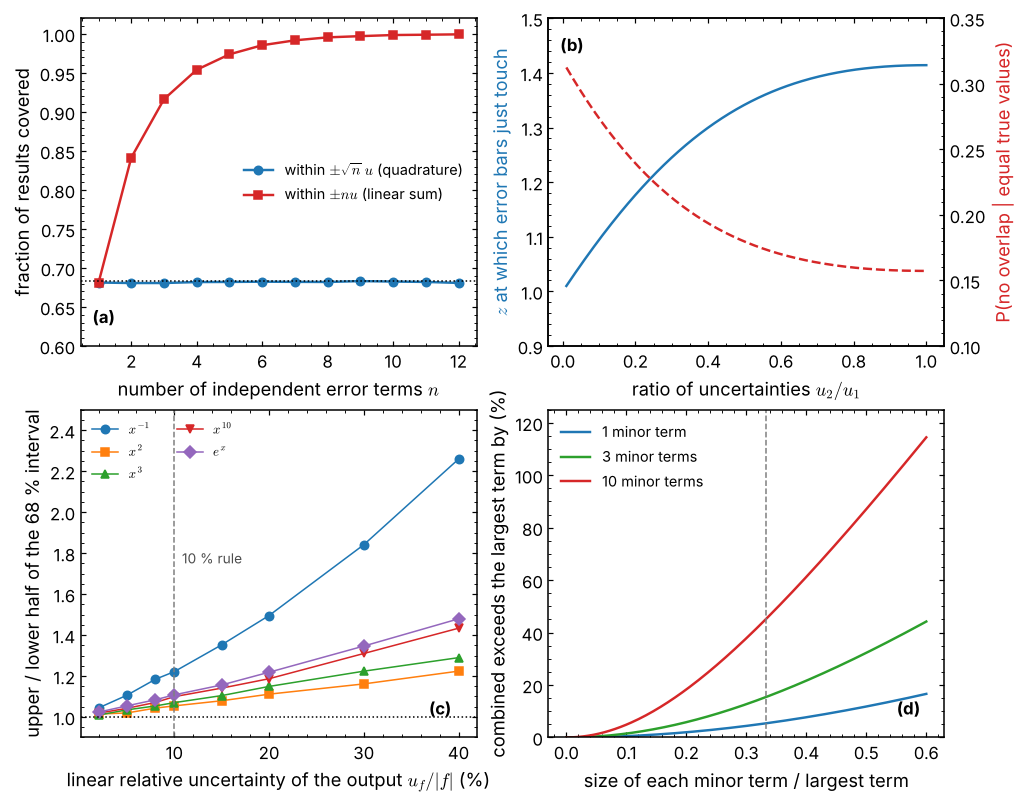

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.2))

ax = axes[0, 0]
ax.plot(n_values, cover_quad, "o-", color="C0", label=r"within $\pm\sqrt{n}\,u$ (quadrature)")
ax.plot(n_values, cover_lin, "s-", color="C3", label=r"within $\pm n u$ (linear sum)")
ax.axhline(0.6827, color="k", ls=":", lw=1)
ax.set_xlabel("number of independent error terms $n$")
ax.set_ylabel("fraction of results covered")
ax.set_ylim(0.6, 1.02); ax.legend(loc="center right"); ep.panel_label(ax, "(a)", y=0.12)

ax = axes[0, 1]
ax.plot(r, z_thr, "C0")
ax.set_xlabel(r"ratio of uncertainties $u_2/u_1$")
ax.set_ylabel(r"$z$ at which error bars just touch", color="C0")
ax.set_ylim(0.9, 1.5)
ax2 = ax.twinx()
ax2.plot(r, p_no_overlap, "C3--")
ax2.set_ylabel("P(no overlap | equal true values)", color="C3")
ax2.set_ylim(0.1, 0.35)
ep.panel_label(ax, "(b)", y=0.95)

ax = axes[1, 0]
markers = dict(zip(lin_res, "os^vD"))
for i, (name, (hw, asym)) in enumerate(lin_res.items()):
    ax.plot(s_out * 100, asym, marker=markers[name], color=f"C{i}", lw=1, label=name)
ax.axhline(1, color="k", ls=":", lw=1)
ax.axvline(10, color="0.5", ls="--", lw=1)
ax.text(10.8, 1.75, "10 % rule", fontsize=9, color="0.3")
ax.set_xlabel(r"linear relative uncertainty of the output $u_f/|f|$ (%)")
ax.set_ylabel("upper / lower half of the 68 % interval")
ax.set_ylim(0.9, 2.5); ax.legend(loc="upper left", ncol=2, fontsize=8.5); ep.panel_label(ax, "(c)", x=0.88, y=0.12)

ax = axes[1, 1]
rr = np.linspace(0, 0.6, 200)
for k, c in ((1, "C0"), (3, "C2"), (10, "C3")):
    ax.plot(rr, 100 * (np.sqrt(1 + k * rr**2) - 1), color=c, label=f"{k} minor term{'s' if k > 1 else ''}")
ax.axvline(1 / 3, color="0.5", ls="--", lw=1)
ax.set_xlabel("size of each minor term / largest term")
ax.set_ylabel("combined exceeds the largest term by (%)")
ax.set_ylim(0, 125); ax.legend(loc="upper left"); ep.panel_label(ax, "(d)", x=0.88, y=0.12)
plt.show()

**(a)** Section 16.1: quadrature keeps its meaning as terms are added; the
linear sum does not. **(b)** Section 16.2: the separation, in standard
uncertainties of the difference, at which error bars just touch, and the
probability that two measurements of the same quantity fail to overlap.
**(c)** Section 16.3: asymmetry of the true 68 % interval against the output
uncertainty predicted by the linear law, for five functions. **(d)** Section
5.6: how much the combined uncertainty exceeds its largest contribution,
that is, what is lost by keeping only the largest (dashed line: the
"three times" threshold).

## Summary

| Rule | Verdict | Holds when |
|---|---|---|
| Add uncertainties (worst case) | a bound, not a standard uncertainty | the $\pm$ values are hard limits and a guarantee is wanted |
| Overlapping bars mean agreement | the threshold is $z \approx 1.4$, not 2 | never as a test; compute $z$ |
| Linear formula for small uncertainties | judge by the output | output relative uncertainty below about 10 % |
| Apply the rules step by step | wrong when an input appears twice | every input appears once |
| Measure many at once | divides once-per-reading errors by $N$ | errors not proportional to the reading; correct count |
| Keep only the largest term | fails when there are many small terms | one or two terms below a third of the largest |
| Significant figures | crude, loses information both ways | no uncertainty analysis is available |
| Meter error does not affect the slope | true for offsets only | the error is a pure offset |
| Calculations never reduce uncertainty | false | (never literally; useful only as a warning) |

## Where these rules come from

Most of the rules appear, with the scope their authors intended, in the
standard textbooks. Course notes and guides are cited only for rules or
examples specific to them.

**Textbooks and standards**

* J. R. Taylor, *An Introduction to Error Analysis*, 2nd ed. (University
  Science Books, 1997). Direct addition as an upper bound and its
  replacement by quadrature for independent errors (ch. 3.3, 3.5–3.6;
  Section 16.1); comparing two results by their margins of error (ch.
  2.3–2.5; 16.2); the stack of sheets (ch. 3.4; 16.5); the failure of
  step-by-step propagation when a variable appears more than once (ch. 3.8;
  16.4); neglecting small contributions (ch. 3.3 and 3.8; 16.6); significant
  figures (ch. 2.2 and 2.8; 16.7); systematic errors (ch. 4.6; 16.8).
* P. R. Bevington and D. K. Robinson, *Data Reduction and Error Analysis for
  the Physical Sciences*, 3rd ed. (McGraw-Hill, 2003), ch. 3. The
  propagation formulas and the approximations behind them (16.1, 16.3,
  16.4).
* JCGM 100:2008, *Evaluation of measurement data — Guide to the expression
  of uncertainty in measurement* (GUM). Corrections for systematic effects
  (clause 3.2; 16.8) and correlated input quantities (clause 5.2; 16.9).

**Articles**

* J. Tellinghuisen, "Statistical error propagation", *J. Phys. Chem. A*
  **105**, 3917 (2001). The 10 % rule (16.3).
* G. Cumming and S. Finch, "Inference by eye: confidence intervals and how
  to read pictures of data", *Am. Psychol.* **60**, 170 (2005). Reading
  overlapping error bars (16.2).

**Course notes and guides**

* G. Chapman, *Practical guide to errors and error propagation*, course
  notes for ENSC 222 (1991). The 15 % criterion and the $x^{10}$ example
  (16.3).
* G. Fantner, *A brief introduction to error analysis and propagation*
  (2011, revised 2013), after texts by V. Lindberg. Taking the largest of
  several uncertainty estimates instead of combining them (16.6).
* University of North Carolina, Department of Physics and Astronomy,
  *Measurement and Uncertainty Analysis Guide* (2022). The upper–lower bound
  method in the form tested, the three-times rule and the photogate
  exercise (16.1, 16.6, 16.8).
* D. M. Harrison, *Experimental errors and error analysis*, Chapter 3 of the
  documentation of *Experimental Data Analyst* (Wolfram Research). The
  voltmeter remark (16.8).
* J. Caldwell and A. Vahidsafa, *Propagation of error*, Chemistry
  LibreTexts. The rule of Section 16.9.

## Exercises

1. One guide reports, for the capacitance example of Section 16.1, an
   upper–lower bound interval *narrower* than the quadrature result. Using
   the stated relative uncertainties (2 %, 5 %, 10 %), show that this cannot
   happen, and find the input values that would produce the reported
   numbers.
2. Two laboratories report $g = 9.807 \pm 0.004$ and $9.817 \pm 0.004$ m/s².
   Do the error bars overlap? What is $z$, and what is the probability of a
   difference at least this large if both are right?
3. Extend the `Naive` class so that it raises an error when the same object
   appears twice in an expression. Why is this still not enough to make it
   safe? (Hint: $y = 2x$; then $x + y$.)
4. A balance reads to 0.1 g with a calibration uncertainty of 0.2 % of the
   reading. Twenty identical coins weigh 115.0 g together. Find the mass of
   one coin with its uncertainty, and compare with weighing one coin.
5. For $f = \ln x$, the relative uncertainty of the output is not a useful
   measure (why?). Restate the 10 % rule for this case and test it.

---

**Previous:** [15. Fitting counts: maximum likelihood](15_maximum_likelihood_fitting.ipynb) &nbsp;·&nbsp; **Next:** [17. Correlated data and block averaging](../part4_advanced/17_correlated_data_and_block_averaging.ipynb)